# 1C. 예측모형 비교 — 검증 구간까지

**과제**: 예측 시점(원점) t에서 부품별 **앞으로 7일(t ~ t+6) 신고 건수 합계**를 맞힌다. 정비 부품 발주와 인력 배치에 쓰는 단위다.

**이 노트북이 답하려는 질문**
1. 나이브("다음 주 = 지난주")보다 얼마나 나은가? 모든 모형을 같은 원점·같은 정보·같은 지표로 비교한다.
2. 그 개선은 어디서 나오는가 — 대여량 예측인가, 신고율 모형인가?
3. 복잡한 모형(LightGBM, 딥러닝)이 단순한 구조(대여량 예측 × 신고율)보다 나은가?
4. 개입·환경 변수와 더위·얼었다 녹은 날은 넣는 편이 나은가? (넣은 것과 뺀 것 비교)
5. 날씨 예보가 틀릴 때 얼마나 나빠지는가?

**지키는 규칙**
- 학습은 2021-04-08 ~ 2023-12-25 원점, 비교는 **검증 구간(2024-01-01 ~ 12-25)**에서만 한다.
- **테스트 구간(2025 ~)은 이 노트북에서 예측도 채점도 하지 않는다.** 검증에서 고른 모형을 고정한 뒤, 사람이 승인하면 한 번만 연다.
- 원점 t에서 쓸 수 있는 것: t−1일까지의 관측값, 미래 7일의 달력, 미래 7일의 날씨(시나리오에 따라). 미래의 대여량·신고는 쓰지 않는다.

**날씨 시나리오**: A 실측(완벽한 예보가 있을 때의 상한) / **C 오차 주입(현실에 가까운 추정. 모형 선택은 이것으로 한다)** / D 날씨 없음(날씨 변수를 뺀 모형)

**지표**: MAE(평균 오차, 건) · MAE%(MAE ÷ 실제 평균) · **skill = 1 − MAE ÷ 나이브 B1의 MAE**(0.10이면 나이브보다 오차가 10% 작다. 음수면 나이브보다 못하다) · bias(예측 − 실제. 양수면 과대예측)

공용 코드: `py/fc.py`(과제 정의·나이브·시나리오·채점), `py/fc_models.py`(음이항·LightGBM·ARIMAX), `py/fc_dl.py`(GRU) · 결과: `output/tables/fc_*.csv`, `output/figures/fc_*.png`

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("../py")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "AppleGothic"; plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 240); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 100)
ROOT = Path("..")
from fc import *
from fc_models import *
from fc_expo import compare_expo, expo_rows, lgb_rounds, fit_expo_lgb, expo_oof
from fc_dl import make_arrays, fit_predict_gru

m = load_master()
base = make_base(m)                                   # 테스트 구간 원점은 만들지 않는다
vi = base[(base.split == "valid") & (base.part == "total_faults")].i.to_numpy()                      # 검증 원점의 행 번호
ti = base[(base.split == "train") & base.clean & (base.part == "total_faults") & (base.origin >= "2021-05-06")].i.to_numpy()
# 학습 원점: 앞 28일 ~ 뒤 6일에 운영 중단·신고 누락인 날이 없는 원점만. 2021-05-06부터인 이유는 과거 4주 값이 모두 2021-04-08 이후(같은 레짐)이도록
# LightGBM·GRU가 '언제 학습을 멈출지' 정할 때 쓰는 원점: 학습 원점의 뒤쪽(2023-03-01 이후). 검증 구간은 이 용도로 쓰지 않는다
HOLD_FROM = int(np.where(m.date >= "2023-03-01")[0][0])
print("그중 멈출 시점을 정하는 데 쓰는 뒤쪽 원점:", int((ti >= HOLD_FROM).sum()), "개 (", m.date[ti[ti >= HOLD_FROM][0]].date(), "~", m.date[ti[-1]].date(), ")")
print("학습 원점", len(ti), "개 /", "검증 원점", len(vi), "개 (", m.date[vi[0]].date(), "~", m.date[vi[-1]].date(), ")")

preds = []                                            # 모든 모형의 검증 예측을 여기에 모은다
def add(df, part, model):
    """모형 하나의 예측 표(oi, pred, [q10, q90])를 공통 형식으로 바꿔 모은다"""
    out = df.assign(origin=m.date.to_numpy()[df.oi.to_numpy()], part=part, model=model)
    preds.append(out[[c for c in ["origin", "part", "model", "pred", "q10", "q90"] if c in out]])

def save_tab(x, name, index=True):
    x.to_csv(ROOT / f"output/tables/fc_{name}.csv", index=index); return x

그중 멈출 시점을 정하는 데 쓰는 뒤쪽 원점: 232 개 ( 2023-03-01 ~ 2023-12-25 )
학습 원점 861 개 / 검증 원점 360 개 ( 2024-01-01 ~ 2024-12-25 )


## 1. 나이브 — 넘어야 할 기준

| 이름 | 방법 |
|---|---|
| **B1** | 지난주 합계 그대로("다음 주 = 지난주"). **skill의 기준** |
| B2 | 최근 4주의 주 평균 |
| B3 | 작년 같은 주 |
| B4 | 작년 같은 주 × 최근 증감률 |

파이프라인이 맞는지 확인하는 숫자: 런북에 적힌 2024년 B1의 MAE%는 타이어 17.8%, 체인 19.1%, 안장 20.2%, 페달 19.8%.

In [2]:
naive = base[base.split == "valid"].melt(id_vars=["origin", "part"], value_vars=["B1", "B2", "B3", "B4"], var_name="model", value_name="pred").dropna()
preds.append(naive)
s = score(naive, base)
save_tab(s.pivot(index="model", columns="part", values="MAEpct").rename(columns=PARTS).round(1), "naive_valid")

part,체인,페달,안장,타이어,전체
model,,,,,
B1,19.1,19.8,20.2,17.8,17.3
B2,22.1,22.8,21.7,20.4,19.8
B3,24.5,21.1,36.6,25.4,21.8
B4,24.0,26.1,24.7,22.0,23.0


## 2. 대여량(노출) 예측

신고 건수 = 대여량 × 신고율이므로, 먼저 **앞으로 7일의 대여량**을 맞혀야 한다(미래의 대여량은 알 수 없다).
아래 4절에서 보듯 남은 오차의 가장 큰 부분이 대여량 예측 오차라서, 대여량 모형의 후보를 먼저 비교해 고른다(`py/fc_expo.py`).

| 후보 | 방법 | 학습에 쓴 날씨 |
|---|---|---|
| E0 | 음이항 회귀(최근 4주 수준, 요일·쉬는 날, 계절, 기온·한파·비·눈). 처음에 쓰던 모형 | 실측 |
| E2 | E0 + 평년 대비 기온 편차와 계절의 상호작용 | 실측 |
| E5 | LightGBM | 실측 |
| N2 | E2와 같은 식 | **예보 오차 섞음** |
| N5 | LightGBM | **예보 오차 섞음** |
| N7 | N2와 N5의 기하평균 | **예보 오차 섞음** |

**예보 오차가 섞인 날씨로 학습한다는 것**: 모형을 쓸 때는 미래 날씨를 예보로만 안다. 학습을 실제 날씨로 하면 모형은 날씨를 100% 믿도록 배우고, 예보가 틀린 날 크게 빗나간다. 학습할 때도 오차가 섞인 날씨를 넣으면 "먼 날의 예보일수록 덜 믿는" 법을 배운다.

**고르는 기준**: 학습 구간 뒤쪽 원점(2023-03-01 ~ 12-25)의 주간 오차율, 날씨 C 조건. 검증 구간(2024)은 확인용이다.

In [3]:
expo_cmp = compare_expo(m)
save_tab(expo_cmp.round(2), "expo_candidates")

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

...

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model pa

/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/Users/junyeop/dareungi/.venv/lib/python3.14/site-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)


,학습에 쓴 날씨,"학습 뒤쪽, 날씨 A","학습 뒤쪽, 날씨 C","검증, 날씨 A","검증, 날씨 C"
모형,,,,,
E0 음이항(처음 모형),실측,8.40,11.08,6.87,10.23
E2 음이항 + 기온 편차·계절,실측,8.07,10.83,6.84,10.20
E5 LightGBM,실측,10.07,11.46,7.47,9.07
N2 음이항 E2,예보 오차 섞음,9.15,9.96,8.43,9.92
N5 LightGBM,예보 오차 섞음,8.96,9.14,7.77,8.26
N7 N2와 N5의 기하평균,예보 오차 섞음,8.21,8.95,7.37,8.49


**선택: N5(예보 오차가 섞인 날씨로 학습한 LightGBM).** 고르는 기준(학습 뒤쪽, 날씨 C)에서 N7과 함께 가장 좋고, 둘의 차이가 작아 더 단순한 N5를 쓴다. 검증 구간에서도 가장 좋다(확인).

시나리오별로 쓰는 대여량 모형
- **C(예보 오차 있음, 모형 선택의 기준)**: N5
- A(완벽한 예보가 있을 때의 상한): E0(실측 날씨로 학습한 음이항). 실제 날씨를 넣을 때는 이쪽이 더 정확하다
- D(날씨 없음): 날씨 변수를 뺀 음이항

In [4]:
expo_model = fit_expo(m)                     # A용: 실측 날씨로 학습한 음이항(E0)
expo_model_nowx = fit_expo(m, weather=False)  # D용: 날씨 없는 음이항
rows_C = expo_rows(m, TRAIN_DAYS[0], TRAIN_DAYS[1], "C")       # C용 학습 행: 예보 오차가 섞인 날씨
ROUNDS = lgb_rounds(rows_C)
expo_lgb = fit_expo_lgb(rows_C, ROUNDS)                         # C용: N5
print("N5의 나무 개수:", ROUNDS, "| 학습 행:", len(rows_C))

F, E = {}, {}                               # F[시나리오] = 검증 원점의 '미래 7일 표', E[시나리오] = 그 표 각 행의 대여량 예측
for scn in "AC":
    F[scn] = future_frame(m, vi, scn)
E["A"] = np.asarray(expo_model.predict(F["A"]))
E["C"] = np.asarray(expo_lgb(F["C"]))
F["D"] = F["A"]; E["D"] = np.asarray(expo_model_nowx.predict(F["D"]))
E0_C = np.asarray(expo_model.predict(F["C"]))                   # 비교용: 처음 쓰던 대여량 모형(E0)에 날씨 C

act = F["A"].groupby("oi").rentals.sum()
wk = lambda hat, scn: pd.Series(np.asarray(hat)).groupby(F[scn].oi.to_numpy()).sum().to_numpy()
rows = [{"방법": "지난주 대여량 그대로", "hat": sum_back(m.rentals, 7).iloc[vi].to_numpy()},
        {"방법": "A: 음이항, 날씨 실측", "hat": wk(E["A"], "A")}, {"방법": "C: N5 LightGBM, 날씨 오차 주입 (선택)", "hat": wk(E["C"], "C")},
        {"방법": "C: 처음 모형 E0, 날씨 오차 주입", "hat": wk(E0_C, "C")}, {"방법": "D: 음이항, 날씨 없음", "hat": wk(E["D"], "D")}]
save_tab(pd.DataFrame([{"방법": r["방법"], "MAE%": float(np.abs(r["hat"] - act.to_numpy()).mean() / act.mean() * 100),
                        "bias%": float((r["hat"] - act.to_numpy()).mean() / act.mean() * 100)} for r in rows]).set_index("방법").round(2), "expo_valid")

N5의 나무 개수: 682 | 학습 행: 6937


,MAE%,bias%
방법,,
지난주 대여량 그대로,15.17,0.00
"A: 음이항, 날씨 실측",6.87,-0.37
"C: N5 LightGBM, 날씨 오차 주입 (선택)",8.26,-0.93
"C: 처음 모형 E0, 날씨 오차 주입",10.25,-2.59
"D: 음이항, 날씨 없음",12.53,-2.12


## 3. 모형들

| 이름 | 무엇 | 날씨 |
|---|---|---|
| S1 | **구조 나이브**: 최근 4주 신고율 × 대여량 예측. 날씨·요일이 신고율에 주는 효과는 쓰지 않는다 | C |
| GLM | **음이항 회귀**: 하루씩 신고율을 예측해 대여량 예측과 곱하고 7일을 더한다(1B 모형의 예측판) | A, C, D |
| GLMx | GLM + 더위 + 얼었다 녹은 날 | C |
| GLM_oracle | GLM에 **실제 대여량**을 넣은 것. 실제로는 쓸 수 없다. "대여량을 완벽히 맞히면 어디까지 되나"를 보는 참고선 | A |
| LGB | **LightGBM**: 원점마다 한 행, 7일 합계를 바로 맞힌다 | C, D |
| LGBx | LGB + 개입·환경 변수 + 더위·얼었다 녹은 날 | C |
| ARIMAX | 전통적 시계열 모형(자기상관 + 달력 + 날씨) | A만 |
| GRU | 딥러닝(순환 신경망). 과거 28일 + 미래 7일 → 구조 나이브 대비 배수 | C |

LightGBM과 GRU는 학습을 오래 할수록 학습 자료를 외워 버리므로 "언제 멈출지"를 정해야 한다. 이것을 검증 구간을 보고 정하면 다른 모형보다 유리해지므로, **학습 구간의 뒤쪽 원점(2023-03-01 이후)**으로 정한 뒤 학습 구간 전체로 다시 맞춘다. 그래서 모든 모형이 검증 구간을 한 번도 보지 않은 같은 조건이다.
| GRUx | GRU + 개입·환경 변수 + 더위·얼었다 녹은 날 | C |
| GRUn | GRU를 **예보 오차가 섞인 날씨 입력으로 학습**한 것(대여량 모형과 같은 생각) | C |
| GLM0, GRU0 | 대여량 예측을 **처음 모형(E0)**으로 했을 때의 GLM, GRU. 대여량 모형을 바꿔서 얼마나 나아졌는지 보는 비교용 | C |

"x"가 붙은 것이 **넣은 것**, 안 붙은 것이 **뺀 것**이다. 같은 모형끼리 비교해 변수 묶음의 쓸모를 본다.

In [5]:
# --- 구조 나이브와 음이항 회귀 -------------------------------------------------------------
glm_alpha = {}
for part in PARTS:
    add(predict_s1(F["C"], part, E["C"]), part, "S1_C")
    fit = fit_glm(m, part); glm_alpha[part] = fit[1]
    for scn in "AC":
        add(predict_glm(fit, F[scn], part, E[scn]), part, f"GLM_{scn}")
    add(predict_glm(fit, F["A"], part, F["A"].rentals.to_numpy()), part, "GLM_oracle")       # 실제 대여량(참고선)
    add(predict_glm(fit_glm(m, part, weather=False), F["D"], part, E["D"]), part, "GLM_D")   # 날씨 없는 모형
    add(predict_glm(fit_glm(m, part, extra=True), F["C"], part, E["C"]), part, "GLMx_C")     # + 더위·얼었다 녹은 날
    add(predict_glm(fit, F["C"], part, E0_C), part, "GLM0_C")                                # 비교용: 처음 쓰던 대여량 모형
print("음이항 모형의 alpha(흩어짐):", {PARTS[k]: round(v, 4) for k, v in glm_alpha.items()})

음이항 모형의 alpha(흩어짐): {'타이어': 0.0079, '체인': 0.0156, '안장': 0.0074, '페달': 0.011, '전체': 0.0144}


In [6]:
# --- LightGBM ---------------------------------------------------------------------------
# 학습은 실측 날씨(A)로 만든 특성으로, 예측은 시나리오 값으로 만든 특성으로 한다
F_tr = future_frame(m, ti, "A"); E_tr_nowx = np.asarray(expo_model_nowx.predict(F_tr))
F_trC = future_frame(m, ti, "C")                    # 학습 원점의 '예보 오차가 섞인' 미래 7일 표
# 학습 원점의 대여량 예측은 교차 예측으로 만든다(대여량 모형이 자기가 학습한 날을 예측하면 실제보다 너무 잘 맞기 때문. py/fc_expo.py의 expo_oof 참고)
E_tr = expo_oof(rows_C, F_trC, ROUNDS)
E_tr0 = np.asarray(expo_model.predict(F_tr))        # 비교용(GRU0): 처음 쓰던 대여량 모형
_w = lambda f, e: pd.Series(np.asarray(e)).groupby(f.oi.to_numpy()).sum().to_numpy()
_a = F_tr.groupby("oi").rentals.sum().to_numpy()
print("학습 원점에서 주간 대여량 예측 오차율: 교차 예측", round(float(np.abs(_w(F_trC, E_tr) - _a).mean() / _a.mean() * 100), 2), "% (검증 구간의 오차율과 비슷해야 한다)")
lgb_imp, lgb_rounds = {}, {}
for part in PARTS:
    yb = base[base.part == part][["i", "y"]].rename(columns={"i": "oi"})
    tr = week_feats(m, part, F_tr, E_tr).merge(yb, on="oi")
    va = {scn: week_feats(m, part, F[scn], E[scn]).merge(yb, on="oi") for scn in "AC"}
    out, imp, rounds = fit_predict_lgb(tr, va["C"], LGB_BASE + LGB_WX, HOLD_FROM)
    add(out, part, "LGB_C"); lgb_imp[PARTS[part]] = imp; lgb_rounds[PARTS[part]] = rounds
    out, imp_x, _ = fit_predict_lgb(tr, va["C"], LGB_BASE + LGB_WX + LGB_EXTRA, HOLD_FROM)
    add(out, part, "LGBx_C"); lgb_imp[PARTS[part] + " (x)"] = imp_x
    # 날씨 없음: 날씨 특성을 빼고, 대여량 예측도 날씨 없는 모형의 것
    tr_d = week_feats(m, part, F_tr, E_tr_nowx).merge(yb, on="oi"); va_d = week_feats(m, part, F["D"], E["D"]).merge(yb, on="oi")
    out, _, _ = fit_predict_lgb(tr_d, va_d, LGB_BASE, HOLD_FROM)
    add(out, part, "LGB_D")
print("나무 개수(학습 구간 뒤쪽 원점의 오차로 정함):", lgb_rounds)

학습 원점에서 주간 대여량 예측 오차율: 교차 예측 11.19 % (검증 구간의 오차율과 비슷해야 한다)


나무 개수(학습 구간 뒤쪽 원점의 오차로 정함): {'타이어': 1682, '체인': 906, '안장': 121, '페달': 377, '전체': 202}


In [7]:
# --- ARIMAX (날씨는 실측값. 이 모형에 가장 유리한 조건) ------------------------------------
arima_order = {}
for part in PARTS:
    out, order = arimax_forecast(m, part, vi)
    add(out, part, "ARIMAX_A"); arima_order[PARTS[part]] = order
print("고른 차수 (p, d, q):", arima_order)

고른 차수 (p, d, q): {'타이어': (0, 1, 2), '체인': (0, 1, 2), '안장': (0, 1, 2), '페달': (2, 1, 2), '전체': (0, 1, 2)}


In [8]:
# --- GRU(딥러닝) -------------------------------------------------------------------------
for part in PARTS:
    y_all = base[base.part == part].set_index("i").y
    for extra, name in ((False, "GRU_C"), (True, "GRUx_C")):
        a_tr = make_arrays(m, part, F_tr, E_tr, extra)                  # 학습 입력: 날씨는 실측, 대여량은 교차 예측
        a_va_pred = make_arrays(m, part, F["C"], E["C"], extra)         # 평가는 오차 주입 날씨 입력
        add(fit_predict_gru(a_tr, y_all.loc[ti].to_numpy(), ti >= HOLD_FROM, a_va_pred), part, name)
    # GRUn: 학습 입력의 날씨도 예보 오차가 섞인 것으로
    add(fit_predict_gru(make_arrays(m, part, F_trC, E_tr), y_all.loc[ti].to_numpy(), ti >= HOLD_FROM, make_arrays(m, part, F["C"], E["C"])), part, "GRUn_C")
    # GRU0: 대여량 예측을 처음 모형(E0)으로(커밋 285e375 때의 구성)
    add(fit_predict_gru(make_arrays(m, part, F_tr, E_tr0), y_all.loc[ti].to_numpy(), ti >= HOLD_FROM, make_arrays(m, part, F["C"], E0_C)), part, "GRU0_C")
print("완료")

완료


## 4. 검증 구간 채점

모든 모형이 예측을 낸 원점만 채점한다. 표의 값은 **skill**(나이브 B1 대비 오차 감소 비율)이다.

In [9]:
valid_preds = pd.concat(preds, ignore_index=True)
sc = score(valid_preds, base)
sc = sc[sc.split == "valid"].drop(columns="split")
save_tab(sc.round(4), "valid", index=False)

ORDER = ["B1", "B2", "B3", "B4", "S1_C", "GLM_C", "GLMx_C", "LGB_C", "LGBx_C", "GRU_C", "GRUx_C", "GRUn_C", "GLM0_C", "GRU0_C", "GLM_D", "LGB_D", "GLM_A", "ARIMAX_A", "GLM_oracle"]
skill = sc.pivot(index="model", columns="part", values="skill").rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())]
print("채점한 원점 수:", int(sc.n.iloc[0]))
print("skill (양수 = 나이브 B1보다 낫다)")
display(skill.round(3))
print("MAE% (오차 ÷ 실제 평균)")
display(sc.pivot(index="model", columns="part", values="MAEpct").rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())].round(1))

채점한 원점 수: 360
skill (양수 = 나이브 B1보다 낫다)


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.000,0.000,0.000,0.000,0.000
B2,-0.151,-0.159,-0.075,-0.152,-0.143
B3,-0.429,-0.282,-0.812,-0.066,-0.263
B4,-0.239,-0.258,-0.221,-0.315,-0.330
S1_C,0.163,0.203,0.296,0.188,0.305
GLM_C,0.344,0.296,0.349,0.299,0.303
GLMx_C,0.346,0.285,0.355,0.293,0.298
LGB_C,0.058,0.159,-0.475,0.234,0.127
LGBx_C,-0.025,0.131,-0.473,0.253,0.121


MAE% (오차 ÷ 실제 평균)


part,타이어,체인,안장,페달,전체
model,,,,,
B1,17.8,19.1,20.2,19.8,17.3
B2,20.4,22.1,21.7,22.8,19.8
B3,25.4,24.5,36.6,21.1,21.8
B4,22.0,24.0,24.7,26.1,23.0
S1_C,14.9,15.2,14.2,16.1,12.0
GLM_C,11.7,13.4,13.2,13.9,12.1
GLMx_C,11.6,13.6,13.0,14.0,12.1
LGB_C,16.7,16.0,29.8,15.2,15.1
LGBx_C,18.2,16.6,29.8,14.8,15.2


In [10]:
print("bias ÷ 실제 평균 (%): 양수 = 과대예측")
ymean = base[base.split == "valid"].groupby("part").y.mean()
b = sc.pivot(index="model", columns="part", values="bias")
display((100 * b / ymean).rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())].round(1))
print("80% 예측구간에 실제값이 든 비율(목표 0.80). 구간을 내는 모형만")
display(sc.dropna(subset=["cover80"]).pivot(index="model", columns="part", values="cover80").rename(columns=PARTS)[list(PARTS.values())].round(2))

bias ÷ 실제 평균 (%): 양수 = 과대예측


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.1,-0.2,0.5,-0.1,0.1
B2,-0.1,-0.1,1.1,-0.3,0.4
B3,12.5,-12.6,29.8,-9.8,7.4
B4,-1.2,0.5,4.1,1.5,1.6
S1_C,-0.9,-0.9,1.2,-0.9,-0.1
GLM_C,5.3,-3.8,1.9,-5.6,2.9
GLMx_C,5.0,-4.0,1.9,-5.5,2.7
LGB_C,11.9,-4.3,28.3,-6.5,11.9
LGBx_C,13.6,-5.6,28.2,-4.2,11.9


80% 예측구간에 실제값이 든 비율(목표 0.80). 구간을 내는 모형만


part,타이어,체인,안장,페달,전체
model,,,,,
GLM0_C,0.422222,0.313889,0.336111,0.347222,0.311111
GLM_A,0.463889,0.294444,0.358333,0.444444,0.338889
GLM_C,0.358333,0.347222,0.3,0.361111,0.288889
GLM_D,0.319444,0.422222,0.272222,0.363889,0.461111
GLM_oracle,0.525,0.483333,0.511111,0.516667,0.480556
GLMx_C,0.352778,0.333333,0.305556,0.35,0.286111
LGB_C,0.213889,0.305556,0.488889,0.408333,0.427778
LGB_D,0.341667,0.427778,0.652778,0.488889,0.625
LGBx_C,0.180556,0.266667,0.497222,0.341667,0.416667


## 5. 개선은 어디서 나오는가

같은 날씨 조건(C)에서 한 단계씩 더해 본다.

| 비교 | 무엇을 보나 |
|---|---|
| B1 → GLM0_C | 나이브 대신 "신고율 모형 × 대여량 예측(처음 모형 E0)" |
| GLM0_C → GLM_C | **대여량 모형을 N5로 바꾼 효과**(음이항) |
| GRU0_C → GRU_C | **대여량 모형을 N5로 바꾼 효과**(GRU) |
| GLM_C → GLM_A | 날씨 예보가 **완벽**하다면 |
| GLM_A → GLM_oracle | 대여량까지 **완벽**히 안다면(쓸 수 없는 참고선) |

구조 나이브(S1)와 신고율 모형의 차이는 4절의 skill 표에서 S1_C와 GLM_C를 비교하면 된다.

In [11]:
steps = ["B1", "GLM0_C", "GLM_C", "GRU0_C", "GRU_C", "GLM_A", "GLM_oracle"]
mae = sc.pivot(index="model", columns="part", values="MAE").rename(columns=PARTS).reindex(steps)[list(PARTS.values())]
display(save_tab(mae.round(1), "decomp_mae"))
print("B1 대비 오차 감소율(%)")
(100 * (1 - mae / mae.loc["B1"])).round(1)

part,타이어,체인,안장,페달,전체
model,,,,,
B1,100.9,139.0,95.4,75.6,471.4
GLM0_C,73.2,108.7,70.2,56.9,358.0
GLM_C,66.2,97.8,62.0,53.0,328.5
GRU0_C,69.3,106.6,68.0,57.9,330.8
GRU_C,74.5,106.3,65.7,59.4,359.4
GLM_A,59.8,88.1,55.3,43.1,289.3
GLM_oracle,45.6,62.6,38.0,33.9,191.8


B1 대비 오차 감소율(%)


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.0,0.0,0.0,0.0,0.0
GLM0_C,27.5,21.8,26.4,24.8,24.1
GLM_C,34.4,29.6,34.9,29.9,30.3
GRU0_C,31.3,23.3,28.7,23.5,29.8
GRU_C,26.1,23.5,31.2,21.4,23.8
GLM_A,40.7,36.6,42.0,43.0,38.6
GLM_oracle,54.8,55.0,60.1,55.2,59.3


## 6. 넣은 것과 뺀 것 — 개입·환경 변수, 더위·얼었다 녹은 날

체크포인트 B·C에서 "유연한 모형에 넣은 것과 뺀 것을 비교해 좋은 쪽을 채택"하기로 한 비교다.
값은 **넣었을 때 skill − 뺐을 때 skill**(%p)이다. 양수면 넣는 편이 낫다.

- GLM: 더위 + 얼었다 녹은 날만 추가(개입 변수는 넣지 않는다. 학습 구간의 연도 수준과 구분되지 않기 때문)
- LightGBM, GRU: 개입·환경 변수 11개 + 더운 날 수 + 얼었다 녹은 날 수 추가

In [12]:
diff = pd.DataFrame({"GLM (+더위·얼었다 녹은 날)": skill.loc["GLMx_C"] - skill.loc["GLM_C"],
                     "LightGBM (+개입 변수 등 13개)": skill.loc["LGBx_C"] - skill.loc["LGB_C"],
                     "GRU (+개입 변수 등 13개)": skill.loc["GRUx_C"] - skill.loc["GRU_C"]}).T * 100
display(save_tab(diff.round(2), "extra_vars"))
print("LightGBM 특성 중요도(오차를 줄이는 데 기여한 비율) 상위 6개")
pd.DataFrame({k: v.head(6).round(3).reset_index().apply(lambda r: f"{r['index']} {r[0]:.2f}", axis=1) for k, v in lgb_imp.items() if "(x)" not in k})

part,타이어,체인,안장,페달,전체
GLM (+더위·얼었다 녹은 날),0.24,-1.14,0.56,-0.58,-0.55
LightGBM (+개입 변수 등 13개),-8.22,-2.84,0.21,1.91,-0.54
GRU (+개입 변수 등 13개),-10.57,-7.77,-57.56,1.19,-14.92


LightGBM 특성 중요도(오차를 줄이는 데 기여한 비율) 상위 6개


,타이어,체인,안장,페달,전체
0,expo_hat 0.39,expo_hat 0.67,expo_hat 0.71,expo_hat 0.67,expo_hat 0.74
1,w_tavg 0.38,w_tavg 0.12,lw_expo 0.10,w_tavg 0.13,w_tavg 0.12
2,rate4w 0.06,rate4w 0.06,w_tavg 0.03,lw_expo 0.05,lw_expo 0.04
3,l4w 0.04,w_rain_sum 0.03,rate4w 0.03,l4w 0.02,doy_s 0.01
4,lw 0.04,lw_expo 0.03,w_tmin 0.03,ly 0.02,rate4w 0.01
5,w_tmax 0.02,l4w 0.02,w_rain_sum 0.02,doy_s 0.02,w_rain_sum 0.01


In [13]:
# 넣은 모형(LGBx)에서 추가 변수들이 실제로 쓰였는가: 추가 변수 13개의 중요도 합
ex = pd.DataFrame({k.replace(" (x)", ""): v.reindex(LGB_EXTRA).fillna(0) for k, v in lgb_imp.items() if "(x)" in k})
print("추가 변수 13개의 중요도 합:", ex.sum().round(3).to_dict())
ex[ex.max(axis=1) > 0.005].round(3)

추가 변수 13개의 중요도 합: {'타이어': 0.005, '체인': 0.019, '안장': 0.005, '페달': 0.007, '전체': 0.004}


,타이어,체인,안장,페달,전체
bikes_active_prev,0.002,0.012,0.004,0.002,0.002


## 7. 날씨 정보의 가치 (검증 구간)

같은 모형을 날씨 조건만 바꿔 본다. A(완벽한 예보) − C(오차 있는 예보) = 예보 오차의 비용, C − D(날씨 없음) = 날씨 정보의 가치.

In [14]:
wx = pd.DataFrame({"GLM A 실측": skill.loc["GLM_A"], "GLM C 오차 주입": skill.loc["GLM_C"], "GLM D 날씨 없음": skill.loc["GLM_D"],
                   "LGB C 오차 주입": skill.loc["LGB_C"], "LGB D 날씨 없음": skill.loc["LGB_D"]}).T
save_tab(wx.round(3), "scenarios_valid")

part,타이어,체인,안장,페달,전체
GLM A 실측,0.407,0.366,0.420,0.430,0.386
GLM C 오차 주입,0.344,0.296,0.349,0.299,0.303
GLM D 날씨 없음,0.228,0.167,0.179,0.172,0.190
LGB C 오차 주입,0.058,0.159,-0.475,0.234,0.127
LGB D 날씨 없음,0.030,0.040,-0.316,0.136,-0.022


## 8. 월요일 원점만 — 운영 관점

실제 운영에서는 매주 한 번(월요일 아침) 그 주의 예측을 낸다. 월요일 원점만 골라 다시 채점한다(원점이 약 52개로 적어 숫자가 더 흔들린다).

In [15]:
mon = valid_preds[valid_preds.origin.dt.dayofweek == 0]
sm_ = score(mon, base); sm_ = sm_[sm_.split == "valid"]
print("월요일 원점 수:", int(sm_.n.iloc[0]))
save_tab(sm_.pivot(index="model", columns="part", values="skill").rename(columns=PARTS).reindex(ORDER)[list(PARTS.values())].round(3), "valid_monday")

월요일 원점 수: 52


part,타이어,체인,안장,페달,전체
model,,,,,
B1,0.000,0.000,0.000,0.000,0.000
B2,-0.152,-0.123,-0.070,-0.071,-0.101
B3,-0.443,-0.278,-0.775,-0.079,-0.269
B4,-0.326,-0.357,-0.235,-0.350,-0.407
S1_C,0.187,0.258,0.313,0.230,0.348
GLM_C,0.403,0.351,0.362,0.340,0.365
GLMx_C,0.401,0.344,0.366,0.334,0.362
LGB_C,0.107,0.275,-0.362,0.272,0.243
LGBx_C,0.034,0.230,-0.358,0.286,0.234


## 9. 부품별 모형 선택 — 체크포인트 D (2026-10-05 확정, 대여량 모형을 바꾼 뒤 다시 판정)

**후보**: 현실적인 조건(날씨 C)의 모형과 나이브. 다음은 후보가 아니다.
- A(완벽한 예보)·oracle(실제 대여량)·D(날씨 없음): 실제로 쓸 수 없거나 비교용 조건
- ARIMAX: 날씨 실측으로만 돌린 참고용
- **개입·환경 변수를 넣은 모형(GLMx, LGBx, GRUx)**: 6절에서 넣어서 나아지지 않았다(GRU는 4개 부품에서 나빠짐, LightGBM은 추가 변수의 중요도 합이 1% 안팎). 뺀 쪽을 채택한다.

**규칙**(런북 04)
1. 검증 skill이 가장 높은 모형을 고른다.
2. 가장 높은 skill이 +3% 미만이면 나이브(B1)를 채택한다.
3. 1위와의 차이가 2%p 미만인 모형 중에서는 더 단순한 것을 고른다(단순한 순서: S1 > GLM > LGB > GRU > GRUn).

대여량 모형을 N5로 바꾼 뒤 다시 적용한 결과다. GLM0·GRU0(처음 대여량 모형)은 비교용이라 후보가 아니다.

결과 표에는 선택 여부와 상관없이 **GRU와 음이항(GLM)을 모든 부품에 함께** 적는다.

**사람의 결정(2026-10-05): 다섯 부품 모두 음이항(GLM_C)으로 통일한다.**
- 규칙을 그대로 적용하면 부품 4개는 음이항, '전체'만 구조 나이브(S1)가 나온다. 전체에서 둘의 차이는 0.2%p로 사실상 같아서, 한 가지 모형으로 통일한다.
- 처음(대여량 모형을 바꾸기 전)에는 GRU로 통일하기로 했었다. 대여량 모형을 N5로 바꾸자 음이항이 5 ~ 9%p 올라 모든 부품에서 GRU를 앞섰고, GRU는 설정에 따라 5%p씩 흔들렸다.
- 검증 구간을 보고 모형을 고치는 일은 여기서 멈춘다(볼수록 검증 점수가 낙관적이 된다).

In [16]:
CAND = ["S1_C", "GLM_C", "LGB_C", "GRU_C", "GRUn_C"]          # 단순한 순서
rows = []
for part, name in PARTS.items():
    s_ = skill[name].reindex(CAND)
    top = s_.max()
    if top < 0.03:
        rule, why = "B1", f"가장 높은 skill {top:.3f}이 0.03 미만"
    else:
        rule = next(c for c in CAND if s_[c] >= top - 0.02)
        why = f"최고 {s_.idxmax()} {top:.3f}" + ("" if rule == s_.idxmax() else f", 2%p 안에서 더 단순한 {rule} {s_[rule]:.3f}")
    pick = "GLM_C"                                   # 사람의 결정: 음이항으로 통일
    why = f"규칙으로는 {rule}({why}). 결정: 음이항으로 통일"
    r = sc[(sc.part == part) & (sc.model == pick)].iloc[0]
    rows.append({"부품": name, "part": part, "선택": pick, "검증 skill": round(float(skill.loc[pick, name]), 3), "검증 MAE": round(r.MAE, 1), "검증 MAE%": round(r.MAEpct, 1),
                 "GLM_C skill(함께 보고)": round(float(skill.loc["GLM_C", name]), 3), "S1_C skill": round(float(skill.loc["S1_C", name]), 3), "근거": why})
sel = pd.DataFrame(rows).set_index("부품")
sel.drop(columns="part")

,선택,검증 skill,검증 MAE,검증 MAE%,GLM_C skill(함께 보고),S1_C skill,근거
부품,,,,,,,
타이어,GLM_C,0.344,66.2,11.7,0.344,0.163,규칙으로는 GLM_C(최고 GLM_C 0.344). 결정: 음이항으로 통일
체인,GLM_C,0.296,97.8,13.4,0.296,0.203,규칙으로는 GLM_C(최고 GLM_C 0.296). 결정: 음이항으로 통일
안장,GLM_C,0.349,62.0,13.2,0.349,0.296,규칙으로는 GLM_C(최고 GLM_C 0.349). 결정: 음이항으로 통일
페달,GLM_C,0.299,53.0,13.9,0.299,0.188,규칙으로는 GLM_C(최고 GLM_C 0.299). 결정: 음이항으로 통일
전체,GLM_C,0.303,328.5,12.1,0.303,0.305,규칙으로는 S1_C(최고 S1_C 0.305). 결정: 음이항으로 통일


## 10. 예측구간 보정

4절에서 본 대로 모형이 낸 80% 구간은 너무 좁다(실제값이 든 비율 23 ~ 53%). 대여량 예측의 오차가 구간에 들어 있지 않기 때문이다. GRU는 구간을 아예 내지 않는다.

그래서 모형이 낸 구간 대신 **검증 구간에서 실제로 얼마나 틀렸는지**로 구간을 만든다.
- 상대오차 r = (실제 − 예측) ÷ 예측 을 검증 원점마다 구한다.
- r의 10% 지점(r_lo)과 90% 지점(r_hi)을 구한다. 예: r_lo = −0.15, r_hi = +0.20이면 "실제는 대체로 예측의 −15% ~ +20% 안에 있었다".
- 새 예측의 80% 구간 = [예측 × (1 + r_lo), 예측 × (1 + r_hi)]

비율로 만들기 때문에 수준이 달라져도(레짐 변화) 덜 흔들린다. 검증 구간에서는 정의상 80%가 들어가므로, 이 구간이 실제로 맞는지는 테스트 구간에서 확인한다.

In [17]:
REPORT = sorted(set(["B1", "S1_C", "GLM_C", "GRU_C"]) | set(sel["선택"]))            # 테스트에서 함께 보고할 모형
vp = valid_preds[valid_preds.model.isin(REPORT)].merge(base[["origin", "part", "y"]], on=["origin", "part"])
vp["r"] = (vp.y - vp.pred) / vp.pred
cal = vp.groupby(["part", "model"]).r.quantile([0.1, 0.9]).unstack().rename(columns={0.1: "r_lo", 0.9: "r_hi"}).reset_index()
cal.to_csv(ROOT / "output/models/interval_calibration.csv", index=False)

# 고정 파일: 부품별 선택 모형과 그 모형의 구간 보정값. 이 파일을 커밋한 뒤에 테스트 구간을 연다
(ROOT / "output/models").mkdir(parents=True, exist_ok=True)
fix = sel.reset_index().merge(cal.rename(columns={"model": "선택"}), on=["part", "선택"])
fix = fix.assign(대여량_모형="N5: LightGBM, 예보 오차 섞인 날씨로 학습", 날씨_시나리오="C(오차 주입)", 학습_원점="2021-05-06 ~ 2023-12-25(선택 후 2024-12-25까지로 다시 학습)", 확정일="2026-10-05")
fix.to_csv(ROOT / "output/models/selection.csv", index=False)
(ROOT / "output/models/selection_draft.csv").unlink(missing_ok=True)
print("상대오차의 10% ~ 90% 범위(검증 구간): 예측의 몇 % 아래 ~ 위에 실제가 있었나")
(100 * cal.assign(part=cal.part.map(PARTS)).pivot(index="model", columns="part", values="r_lo")[list(PARTS.values())].reindex(REPORT)).round(0).astype(int).astype(str) + " ~ +" + \
(100 * cal.assign(part=cal.part.map(PARTS)).pivot(index="model", columns="part", values="r_hi")[list(PARTS.values())].reindex(REPORT)).round(0).astype(int).astype(str)

상대오차의 10% ~ 90% 범위(검증 구간): 예측의 몇 % 아래 ~ 위에 실제가 있었나


part,타이어,체인,안장,페달,전체
model,,,,,
B1,-25 ~ +34,-27 ~ +39,-30 ~ +42,-29 ~ +49,-25 ~ +35
GLM_C,-21 ~ +16,-17 ~ +37,-25 ~ +24,-16 ~ +34,-20 ~ +21
GRU_C,-25 ~ +11,-24 ~ +34,-29 ~ +12,-19 ~ +35,-31 ~ +11
S1_C,-24 ~ +23,-24 ~ +32,-26 ~ +24,-23 ~ +31,-19 ~ +23


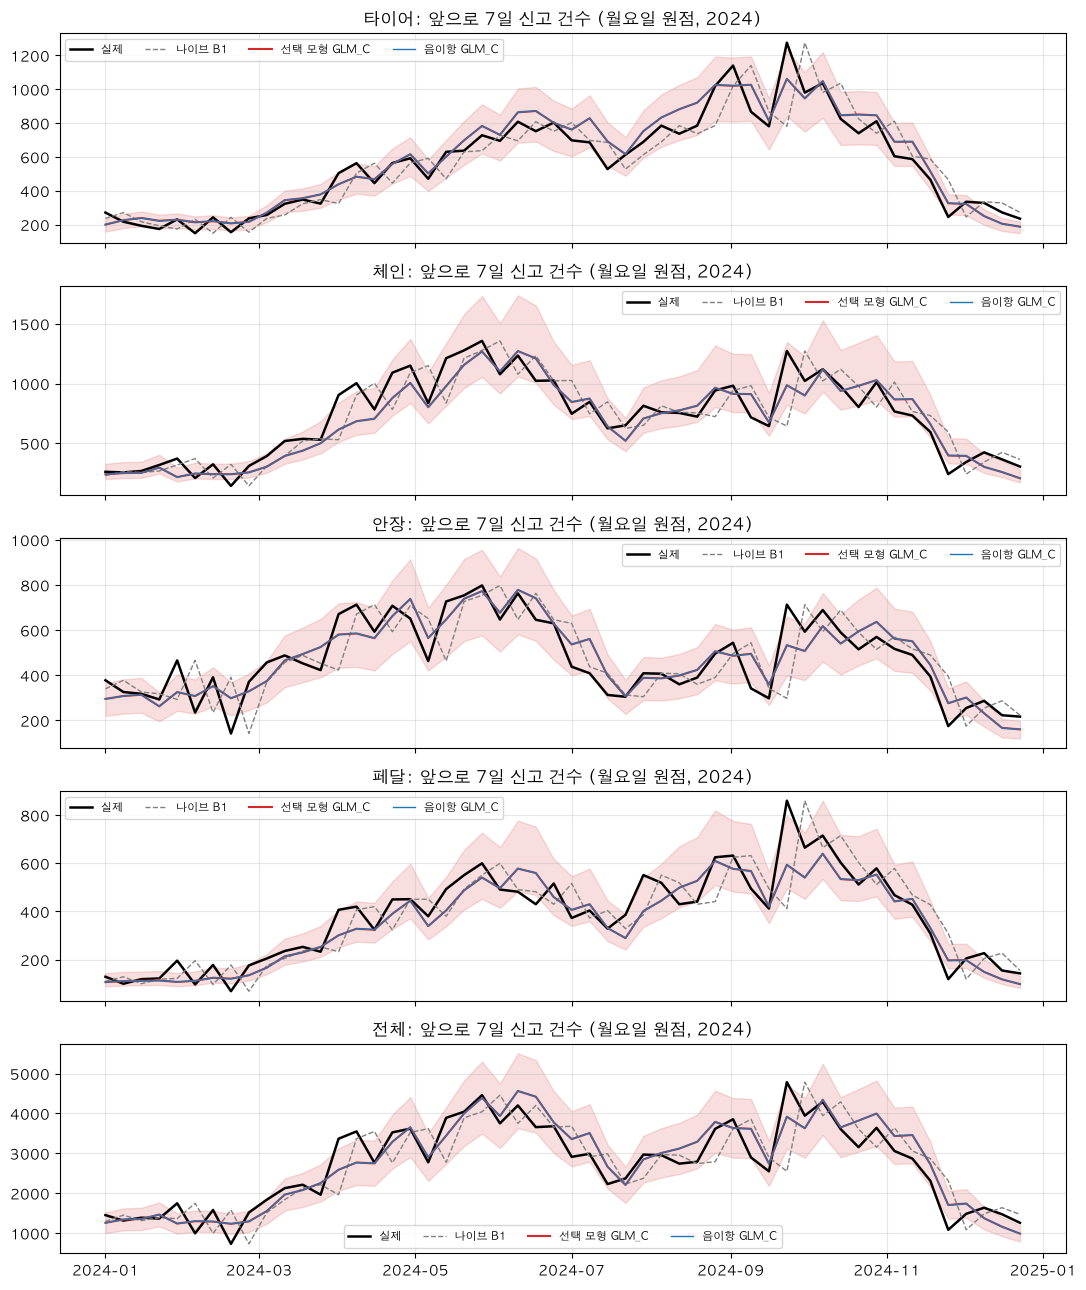

In [18]:
# 선택 모형의 검증 구간 주간 예측과 실제(월요일 원점만 이어서 그린다). 띠는 보정한 80% 구간
fig, axes = plt.subplots(len(PARTS), 1, figsize=(11, 2.6 * len(PARTS)), sharex=True)
for ax, (part, name) in zip(axes, PARTS.items()):
    pick = sel.loc[name, "선택"]; c_ = cal[(cal.part == part) & (cal.model == pick)].iloc[0]
    a = base[(base.part == part) & (base.split == "valid") & (base.origin.dt.dayofweek == 0)].set_index("origin")
    p = valid_preds[(valid_preds.part == part) & (valid_preds.model == pick) & (valid_preds.origin.dt.dayofweek == 0)].set_index("origin")
    ax.plot(a.index, a.y, color="black", lw=1.8, label="실제")
    ax.plot(a.index, a.B1, color="gray", lw=1, ls="--", label="나이브 B1")
    ax.plot(p.index, p.pred, color="tab:red", lw=1.5, label=f"선택 모형 {pick}")
    ax.fill_between(p.index, p.pred * (1 + c_.r_lo), p.pred * (1 + c_.r_hi), color="tab:red", alpha=0.15)
    g = valid_preds[(valid_preds.part == part) & (valid_preds.model == "GLM_C") & (valid_preds.origin.dt.dayofweek == 0)].set_index("origin")
    ax.plot(g.index, g.pred, color="tab:blue", lw=1, label="음이항 GLM_C")
    ax.set_title(f"{name}: 앞으로 7일 신고 건수 (월요일 원점, 2024)"); ax.grid(alpha=0.3); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(ROOT / "output/figures/fc_valid_selected.png", dpi=200, bbox_inches="tight"); plt.show()

## 다음에 할 일

**테스트 구간(2025-01-01 ~ 2026-06-24)은 아직 열지 않는다**(사람의 결정, 2026-10-05).
여는 시점: 모형에 영향을 줄 수 있는 작업이 모두 끝나고, `output/models/selection.csv`가 커밋된 뒤, 사람이 승인했을 때 한 번만.

열 때 하는 일(코드는 그때 추가한다)
1. 선택 모형과 함께 보고할 모형(B1, S1, GLM, GRU)을 학습 + 검증 원점(~ 2024-12-25)으로 다시 맞춘다.
2. 테스트 원점을 예측하고 채점한다: 부품별 skill, 2025 상반기·하반기·2026 상반기별, 편향, 월요일 원점만.
3. 보정한 80% 구간에 실제값이 든 비율을 확인한다.
4. 날씨 시나리오 A·C·D별 성능을 비교한다.